# Issue #20 — Improve crossover timing forecasts

Run **all cells in order** to reproduce the original result, compare corrected models with the historical baseline, and view the results here.

This notebook uses the shared implementation in `src/timing_model.py`. It reads cached local data, makes no market-data requests, and saves its reports under `results/issue-20/`.

**Prerequisite:** run notebook **02_clean_features.ipynb** to create `data/processed/zn_roll_panel.parquet`. Notebooks 05–08 are not required. Select the Python kernel with the packages from `requirements-model.txt` installed. If needed, run `%pip install -r ../requirements-model.txt` when your working directory is `notebooks/`, then restart the kernel.


## 1. Locate the project and choose evaluation settings

The default forecast is made at panel day -10 using at least eight completed earlier rolls. Candidate selection uses earlier training rolls only. Keep these defaults for the documented comparison; changing settings after inspecting scores is exploratory research.


In [19]:
from pathlib import Path
import json
import os
import subprocess
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src" / "timing_model.py").is_file()
     and (p / "notebooks").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open this notebook from inside the futures-project repository.")

panel_path = project_root / "data/processed/zn_roll_panel.parquet"
if not panel_path.is_file():
    raise FileNotFoundError("Run 02_clean_features.ipynb first to create the cached roll panel.")

DECISION_DAY = -10
MIN_TRAIN_ROLLS = 8
output_dir = project_root / "results/issue-20"
print("Project:", project_root)
print("Input:", panel_path)


Project: /Users/jacoblerner/Desktop/UChicago/Classes/Futures/futures-project
Input: /Users/jacoblerner/Desktop/UChicago/Classes/Futures/futures-project/data/processed/zn_roll_panel.parquet


## 2. Run the comparison

The original notebook's forecasts are reproduced separately. The corrected models preserve missing decision-day values and fill them using historical training data only. Ridge regression limits large coefficients; the selection procedure can keep the historical baseline when the extra predictors do not help.

This runs the same command-line implementation as `python -m src.timing_model` using this notebook kernel's Python environment.


In [20]:
environment = os.environ.copy()
environment.setdefault("MPLBACKEND", "Agg")
environment.setdefault("MPLCONFIGDIR", str(output_dir / "matplotlib-cache"))
completed = subprocess.run(
    [sys.executable, "-m", "src.timing_model",
     "--decision-day", str(DECISION_DAY),
     "--min-train-rolls", str(MIN_TRAIN_ROLLS)],
    cwd=project_root, env=environment, text=True, capture_output=True,
)
if completed.returncode:
    raise RuntimeError(completed.stderr or completed.stdout)
print(completed.stdout)


Legacy notebook reproduction (MAE):
legacy_ols_absolute_error           1.000000
historical_median_absolute_error    0.263158

            model  rolls      mae  worst_error  mae_minus_baseline  wins  ties  losses
historical_median     19 0.263158            1            0.000000     0    19       0
 ridge_reduced_10     19 0.421053            2            0.157895     0    17       2
   ridge_full_100     19 0.315789            1            0.052632     0    18       1
    ridge_full_10     19 0.368421            2            0.105263     1    16       2
         ols_asof     19 0.631579            3            0.368421     3     9       7
         selected     19 0.263158            1            0.000000     0    19       0

Saved comparison, date audit, figure and report to results/issue-20



## 3. Compare forecast accuracy

Lower mean absolute error (**MAE**) is better. Units count upstream panel observations; exchange-session and publication timing are not independently verified.

`ols_asof` is the original unregularized fitting method with corrected snapshots. `selected` is the model chosen using training history only. Fixed candidate scores are diagnostics: selecting the best after reading this table would reuse the test outcomes.


,model,rolls,mae,worst_error,mae_minus_baseline,wins,ties,losses
0,historical_median,19,0.263,1,0.000,0,19,0
1,ridge_reduced_10,19,0.421,2,0.158,0,17,2
2,ridge_full_100,19,0.316,1,0.053,0,18,1
3,ridge_full_10,19,0.368,2,0.105,1,16,2
4,ols_asof,19,0.632,3,0.368,3,9,7
5,selected,19,0.263,1,0.000,0,19,0


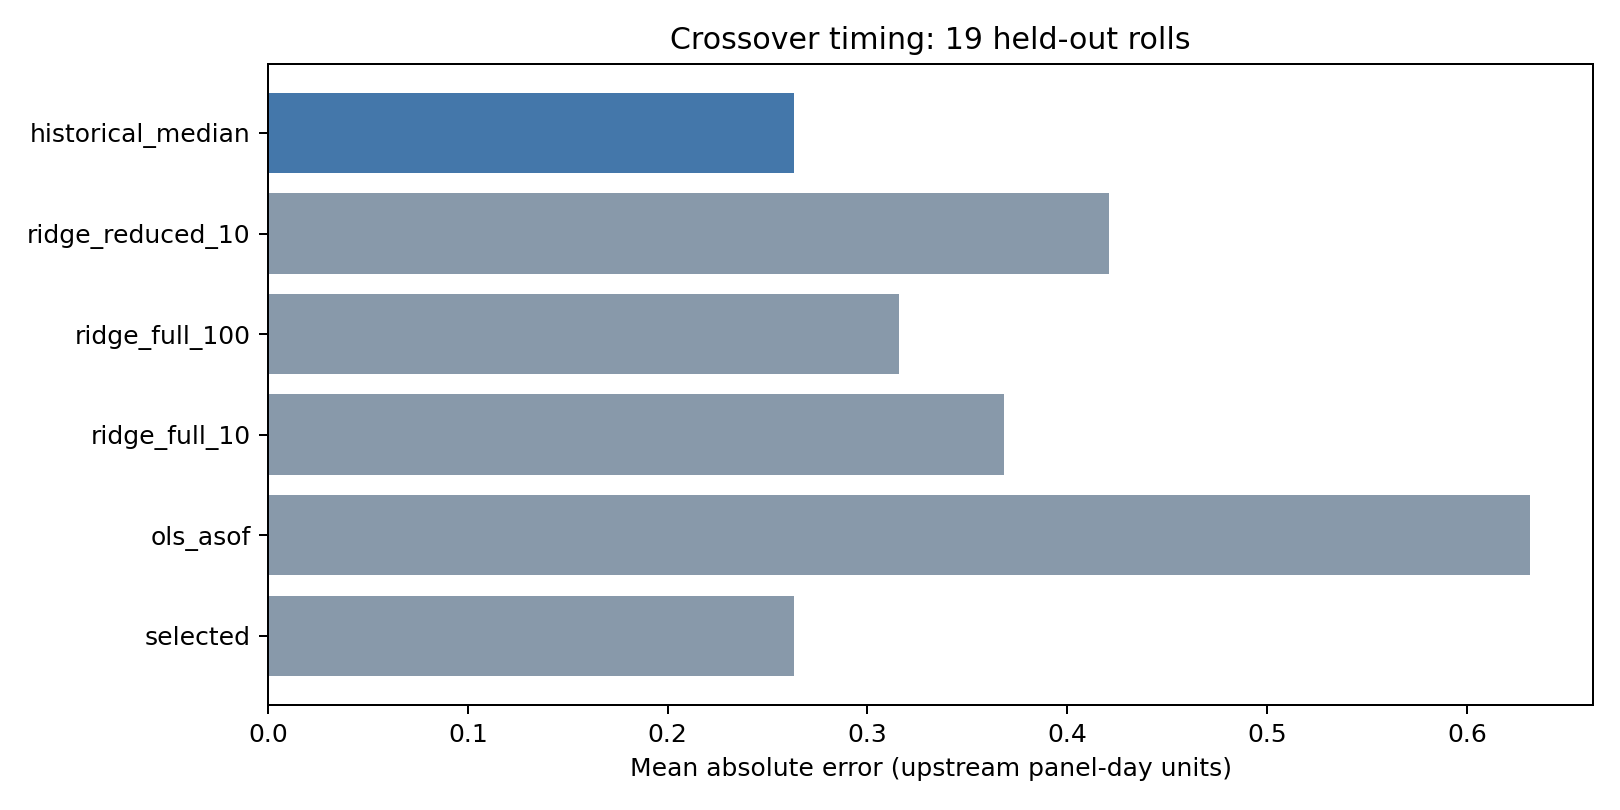

,Legacy reproduction MAE
legacy_ols_absolute_error,1.000000
historical_median_absolute_error,0.263158


In [21]:
summary = pd.read_csv(output_dir / "summary.csv")
display(summary.round(3))
display(Image(filename=str(output_dir / "timing_mae.png")))

legacy = pd.read_csv(output_dir / "legacy_predictions.csv")
display(legacy[["legacy_ols_absolute_error", "historical_median_absolute_error"]]
        .mean().rename("Legacy reproduction MAE").to_frame())


## 4. Inspect predictions and model choices

There is one forecast per held-out quarterly roll. The `selected_model` column shows which rule the training-only comparison chose. `latest_training_end` must be earlier than `decision_date`.


In [22]:
predictions = pd.read_csv(output_dir / "predictions.csv")
selected = predictions.loc[predictions["model"] == "selected"].copy()
display(selected[["roll_id", "selected_model", "decision_date", "training_rolls",
                  "actual", "prediction", "absolute_error"]])
display(selected["selected_model"].value_counts().rename("Test rolls").to_frame())

inner_validation = pd.read_csv(output_dir / "inner_validation.csv")
display(inner_validation.head(12))


,roll_id,selected_model,decision_date,training_rolls,actual,prediction,absolute_error
5,ZNH2->ZNM2,historical_median,2022-02-16,8,-2,-2,0
11,ZNM2->ZNU2,historical_median,2022-05-19,9,-3,-2,1
17,ZNU2->ZNZ2,historical_median,2022-08-19,10,-2,-2,0
23,ZNZ2->ZNH3,historical_median,2022-11-18,11,-2,-2,0
29,ZNH3->ZNM3,historical_median,2023-02-16,12,-2,-2,0
35,ZNM3->ZNU3,historical_median,2023-05-19,13,-2,-2,0
41,ZNU3->ZNZ3,historical_median,2023-08-20,14,-2,-2,0
47,ZNZ3->ZNH4,historical_median,2023-11-19,15,-2,-2,0
53,ZNH4->ZNM4,historical_median,2024-02-18,16,-1,-2,1
59,ZNM4->ZNU4,historical_median,2024-05-20,17,-2,-2,0


,Test rolls
selected_model,
historical_median,19


,roll_id,candidate,inner_mae,inner_rolls,selected
0,ZNH2->ZNM2,historical_median,0.00,2,True
1,ZNH2->ZNM2,ridge_reduced_10,0.00,2,False
2,ZNH2->ZNM2,ridge_full_100,0.00,2,False
3,ZNH2->ZNM2,ridge_full_10,0.00,2,False
4,ZNM2->ZNU2,historical_median,0.00,3,True
5,ZNM2->ZNU2,ridge_reduced_10,0.00,3,False
6,ZNM2->ZNU2,ridge_full_100,0.00,3,False
7,ZNM2->ZNU2,ridge_full_10,0.00,3,False
8,ZNU2->ZNZ2,historical_median,0.25,4,True
9,ZNU2->ZNZ2,ridge_reduced_10,0.25,4,False


## 5. Audit dates and sensitivity

Sunday labels may reflect timestamp conventions; they are not automatically bad observations. The stored data does not retain the original timestamps needed to resolve session labels or open-interest publication timing. Matching the supplied First Notice Day (FND) is a consistency check, not independent calendar validation.

The sensitivity table omits one test roll's error at a time, without refitting. Negative error differences favor the candidate over the baseline.


In [23]:
audit = pd.read_csv(output_dir / "date_audit.csv")
display(audit)
print("Sunday-labeled observations:", int(audit["sunday_rows"].sum()))

sensitivity = pd.read_csv(output_dir / "sensitivity.csv")
display(sensitivity.groupby("model")["paired_mae_minus_baseline"].agg(["min", "max"]).round(3))


,roll_id,observations,sunday_rows,saturday_rows,offset_gaps,offset_zero_date,supplied_fnd,offset_zero_matches_supplied_fnd
0,ZNH0->ZNM0,31,5,0,0,2020-02-28,2020-02-28,True
1,ZNH1->ZNM1,31,5,0,0,2021-02-26,2021-02-26,True
2,ZNH2->ZNM2,31,6,0,0,2022-02-28,2022-02-28,True
3,ZNH3->ZNM3,31,5,0,0,2023-02-28,2023-02-28,True
4,ZNH4->ZNM4,31,5,0,0,2024-02-29,2024-02-29,True
5,ZNH5->ZNM5,31,5,0,0,2025-02-28,2025-02-28,True
6,ZNH6->ZNM6,31,5,0,0,2026-02-27,2026-02-27,True
7,ZNM0->ZNU0,31,5,0,0,2020-05-29,2020-05-29,True
8,ZNM1->ZNU1,31,6,0,0,2021-05-31,2021-05-31,True
9,ZNM2->ZNU2,31,5,0,0,2022-05-31,2022-05-31,True


Sunday-labeled observations: 140


,min,max
model,,
historical_median,0.000,0.000
ols_asof,0.222,0.444
ridge_full_10,0.000,0.167
ridge_full_100,0.000,0.056
ridge_reduced_10,0.056,0.167
selected,0.000,0.000


## 6. Read the findings

This comparison concerns crossover **date** forecasts. The separate notebook `07_predict_crossover.ipynb` forecasts event **probabilities** over 1-, 3-, and 5-day horizons; its scores cannot be directly compared with timing MAE. Neither task establishes lower transaction costs.


In [24]:
display(Markdown((output_dir / "report.md").read_text()))
print("All generated files:", output_dir)


# Issue #20: Crossover timing comparison

Retain the historical-median rule: nested selection did not improve on it.

| Model | Test rolls | MAE (panel days) | Worst error | MAE minus baseline |
|---|---:|---:|---:|---:|
| historical_median | 19 | 0.263 | 1 | +0.000 |
| ridge_reduced_10 | 19 | 0.421 | 2 | +0.158 |
| ridge_full_100 | 19 | 0.316 | 1 | +0.053 |
| ridge_full_10 | 19 | 0.368 | 2 | +0.105 |
| ols_asof | 19 | 0.632 | 3 | +0.368 |
| selected | 19 | 0.263 | 1 | +0.000 |

## Interpretation and limits

Only `selected` represents the training-only model selection policy. The fixed candidates are diagnostics; choosing the best after seeing test scores would reuse the test set. `ols_asof` uses the original OLS fitting method with corrected snapshots. `legacy_predictions.csv` separately reproduces the old notebook's column-wise snapshot selection.

The audit contains 140 Sunday-labeled rows. Offsets count observed upstream dates, not verified exchange business days. Raw extracts retain dates but discard original event/publication timestamps. Exchange-session alignment, holidays and OI publication availability therefore remain unverified. These are provisional comparisons using recorded dates, not a validated live trading backtest. No dates are silently shifted.

Every signal is used no earlier than the next panel observation. Historical windows must end before the test decision date. Imputation, scaling and inner model selection use training rolls only. Missing events cannot be scored.

Sensitivity results drop one test roll's error at a time without refitting; they describe dependence on individual outcomes, not confidence intervals. The sample is small and has already been explored in prior work.

This module forecasts a crossover date. The separate `src.crossover_model` module forecasts 1/3/5-day event probabilities, scored with Brier score and log loss. Those scores cannot be directly compared with timing MAE. Neither timing accuracy nor these comparisons establish lower transaction costs.

Offset zero differs from the supplied FND for **0 rolls**. See `date_audit.csv` before interpreting these as FND business-day forecasts.

## Leave-one-roll-out error sensitivity

Negative values favor the candidate over the baseline.

- historical_median: +0.000 to +0.000 panel days.
- ridge_reduced_10: +0.056 to +0.167 panel days.
- ridge_full_100: +0.000 to +0.056 panel days.
- ridge_full_10: +0.000 to +0.167 panel days.
- ols_asof: +0.222 to +0.444 panel days.
- selected: +0.000 to +0.000 panel days.

## Legacy reproduction

legacy_ols_absolute_error           1.000000
historical_median_absolute_error    0.263158


All generated files: /Users/jacoblerner/Desktop/UChicago/Classes/Futures/futures-project/results/issue-20


## 7. Exploratory improvements: later signals and volume trajectory

This follow-up was designed **after inspecting the original test results**. It is exploratory, not a new untouched test set. It leaves the original evaluation above unchanged.

Compare forecasts made at **-10** and **-5** panel days on the same held-out rolls. Later forecasts have more information but provide less advance notice. A new `trend_shrunk` candidate extrapolates the log-odds of the last five volume shares to the 50% crossover, corrects its historical bias using earlier rolls, and pulls that estimate halfway toward the historical baseline.

The candidate still has to beat the baseline in training-only validation. Do not pick a model or decision cutoff based on these final test scores and call it independent confirmation.


In [25]:
exploratory = subprocess.run(
    [sys.executable, "-m", "src.timing_experiments"],
    cwd=project_root, env=environment, text=True, capture_output=True,
)
if exploratory.returncode:
    raise RuntimeError(exploratory.stderr or exploratory.stdout)
print(exploratory.stdout)


            model  rolls      mae  worst_error  mae_minus_baseline  wins  ties  losses  decision_cutoff  excluded_test_rolls
historical_median     19 0.263158            1            0.000000     0    19       0              -10                    0
 ridge_reduced_10     19 0.421053            2            0.157895     0    17       2              -10                    0
   ridge_full_100     19 0.315789            1            0.052632     0    18       1              -10                    0
    ridge_full_10     19 0.368421            2            0.105263     1    16       2              -10                    0
     trend_shrunk     19 1.210526            3            0.947368     3     3      13              -10                    0
         ols_asof     19 0.631579            3            0.368421     3     9       7              -10                    0
         selected     19 0.263158            1            0.000000     0    19       0              -10                    0


In [26]:
exploratory_dir = output_dir / "exploratory"
exploratory_summary = pd.read_csv(exploratory_dir / "summary.csv")
display(exploratory_summary.pivot(index="model", columns="decision_cutoff", values="mae").round(3))
display(Markdown((exploratory_dir / "report.md").read_text()))


decision_cutoff,-10,-5
model,,
historical_median,0.263,0.263
ols_asof,0.632,0.579
ridge_full_10,0.368,0.368
ridge_full_100,0.316,0.263
ridge_reduced_10,0.421,0.316
selected,0.263,0.263
trend_shrunk,1.211,0.632


# Exploratory timing improvements

Designed after inspecting the original test sample. These results need confirmation on new data. The default model comparison is unchanged.

The trajectory model fits a line to the log-odds of the five most recent volume shares, extrapolates to 50%, corrects its typical bias using prior rolls, and pulls the prediction halfway toward the historical median.

Comparisons use identical test rolls at both cutoffs. Later forecasts have more information and less lead time; they are a different task.

| Cutoff | Model | Rolls | MAE (panel days) | MAE minus baseline |
|---:|---|---:|---:|---:|
| -10 | historical_median | 19 | 0.263 | +0.000 |
| -10 | ridge_reduced_10 | 19 | 0.421 | +0.158 |
| -10 | ridge_full_100 | 19 | 0.316 | +0.053 |
| -10 | ridge_full_10 | 19 | 0.368 | +0.105 |
| -10 | trend_shrunk | 19 | 1.211 | +0.947 |
| -10 | ols_asof | 19 | 0.632 | +0.368 |
| -10 | selected | 19 | 0.263 | +0.000 |
| -5 | historical_median | 19 | 0.263 | +0.000 |
| -5 | ridge_reduced_10 | 19 | 0.316 | +0.053 |
| -5 | ridge_full_100 | 19 | 0.263 | +0.000 |
| -5 | ridge_full_10 | 19 | 0.368 | +0.105 |
| -5 | trend_shrunk | 19 | 0.632 | +0.368 |
| -5 | ols_asof | 19 | 0.579 | +0.316 |
| -5 | selected | 19 | 0.263 | +0.000 |

Only `selected` measures training-only candidate selection. Do not choose a model or cutoff by its final test score and call that fresh out-of-sample evidence. The current session-label and OI publication-time limitations still apply. Timing accuracy does not establish cheaper execution.


## 8. Nested grid search: strengths and feature sets

Search **15 ridge configurations**: five regularization strengths (`0.1, 1, 10, 100, 1000`) crossed with three feature sets (volume, open interest, and all six liquidity features). The historical-median baseline is also eligible. Both decision cutoffs (-10 and -5) are evaluated separately on their common held-out rolls.

For each test roll, the grid search chooses a configuration using expanding validation within earlier completed rolls only. Missing-value replacement and scaling are fitted inside each split. Ties favor the baseline. The earliest test folds have only two inner validation rolls, so tuning is uncertain.

This grid was designed after examining this historical sample. Treat it as **exploratory** and confirm any promising finding on new data. The grid remains deliberately small for our small number of rolls.


In [27]:
grid_run = subprocess.run(
    [sys.executable, "-m", "src.timing_grid_search"],
    cwd=project_root, env=environment, text=True, capture_output=True,
)
if grid_run.returncode:
    raise RuntimeError(grid_run.stderr or grid_run.stdout)
print(grid_run.stdout)


            model  rolls      mae  worst_error  mae_minus_baseline  wins  ties  losses  decision_cutoff  excluded_test_rolls
historical_median     19 0.263158            1                 0.0     0    19       0              -10                    0
         selected     19 0.263158            1                 0.0     0    19       0              -10                    0
historical_median     19 0.263158            1                 0.0     0    19       0               -5                    0
         selected     19 0.263158            1                 0.0     0    19       0               -5                    0

Configurations chosen using earlier rolls:
decision_cutoff  selected_model   
-10              historical_median    19
-5               historical_median    19

Full grid diagnostics and report saved to results/issue-20/grid-search



In [28]:
grid_dir = output_dir / "grid-search"
grid_summary = pd.read_csv(grid_dir / "summary.csv")
grid_policy = grid_summary.loc[grid_summary["model"].isin(["historical_median", "selected"])]
display(grid_policy[["decision_cutoff", "model", "rolls", "mae", "mae_minus_baseline"]].round(3))

grid_choices = pd.read_csv(grid_dir / "selected_models.csv")
display(grid_choices.groupby(["decision_cutoff", "selected_model"]).size().rename("Test rolls").to_frame())
display(Markdown((grid_dir / "report.md").read_text()))


,decision_cutoff,model,rolls,mae,mae_minus_baseline
0,-10,historical_median,19,0.263,0.0
17,-10,selected,19,0.263,0.0
18,-5,historical_median,19,0.263,0.0
35,-5,selected,19,0.263,0.0


,,Test rolls
decision_cutoff,selected_model,
-10,historical_median,19
-5,historical_median,19


# Exploratory nested grid search

Search: 3 feature sets × 5 ridge strengths = 15 learned configurations, plus the historical-median baseline. Two cutoffs are evaluated separately.

Each test roll is held out while the configuration is selected through expanding validation inside earlier completed rolls. Preprocessing uses each training split only. Baseline wins validation ties.

| Cutoff | Policy | Rolls | MAE (panel days) | Difference from baseline |
|---:|---|---:|---:|---:|
| -10 | historical_median | 19 | 0.263 | +0.000 |
| -10 | selected | 19 | 0.263 | +0.000 |
| -5 | historical_median | 19 | 0.263 | +0.000 |
| -5 | selected | 19 | 0.263 | +0.000 |

## Interpretation

The `selected` rows measure the grid-search policy on held-out rolls. The individual candidate scores in `summary.csv` are diagnostics. Choosing the best candidate or cutoff from those final scores reuses the test set.

This search was proposed after examining the same historical sample. Nested validation prevents direct per-fold tuning leakage, but does not make this an untouched research test set. Confirm any improvement on new rolls or independently validated additional history. The earliest outer folds have only two inner validation rolls, so selection is uncertain.

Relative days retain the upstream session-label and OI availability limitations. The -5 cutoff has more recent information and less lead time than -10. Timing MAE is not a measurement of execution costs.


### Individual configurations: diagnostic scores

This table shows all fixed candidates. Selecting a winner from these final test scores would reuse the test set. The `selected` policy above is the valid measure of the training-only grid search.


In [29]:
display(grid_summary.pivot(index="model", columns="decision_cutoff", values="mae").round(3))
# Per-roll tuning choices and validation scores are also available for inspection:
grid_validation = pd.read_csv(grid_dir / "inner_validation.csv")
display(grid_validation.loc[grid_validation["selected"]].head(12))


decision_cutoff,-10,-5
model,,
historical_median,0.263,0.263
ols_asof,0.632,0.579
ridge_full_a0.1,0.526,0.474
ridge_full_a1,0.421,0.421
ridge_full_a10,0.368,0.368
ridge_full_a100,0.316,0.263
ridge_full_a1000,0.263,0.263
ridge_open_interest_a0.1,0.368,0.368
ridge_open_interest_a1,0.368,0.368


,roll_id,candidate,inner_mae,inner_rolls,selected,decision_cutoff
0,ZNH2->ZNM2,historical_median,0.000000,2,True,-10
16,ZNM2->ZNU2,historical_median,0.000000,3,True,-10
32,ZNU2->ZNZ2,historical_median,0.250000,4,True,-10
48,ZNZ2->ZNH3,historical_median,0.200000,5,True,-10
64,ZNH3->ZNM3,historical_median,0.166667,6,True,-10
80,ZNM3->ZNU3,historical_median,0.142857,7,True,-10
96,ZNU3->ZNZ3,historical_median,0.125000,8,True,-10
112,ZNZ3->ZNH4,historical_median,0.111111,9,True,-10
128,ZNH4->ZNM4,historical_median,0.100000,10,True,-10
144,ZNM4->ZNU4,historical_median,0.181818,11,True,-10
